# Exploratory data analysis — C3H/HeJ mouse EEG

The dataset is 50 MATLAB files with a four-line description and no documentation. This
notebook establishes what is actually in it, and derives the parameters the detection
pipeline needs — window length, merge gap, minimum duration — from measurement rather
than from the assumptions in the project specification.

Six of the findings below are undocumented by the dataset itself, and one of them would
silently corrupt any model trained without accounting for it.

All logic is imported from `src/mouse_seizure/`; this notebook contains narrative and
figures only.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from mouse_seizure import config
from mouse_seizure.io import events, load_recording
from mouse_seizure.preprocess import (
    bandpass, frame, frame_labels, resample_labels, resample_to, zscore,
)
from mouse_seizure.summary import all_event_durations, all_event_gaps, dataset_table

# Reference palette, light mode: slot 1 (blue) and slot 2 (orange).
SWD, BASE = "#2a78d6", "#eb6834"
INK, MUTED, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e5e4e0", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10, "figure.dpi": 110,
    "lines.linewidth": 1.2,
})

## 1. What is actually in the dataset

Two splits with entirely different characteristics. Note the row counts: the training
split is **8 mice recorded five days each**, not 18 — the other 10 mice appear only in
the test split.

In [2]:
table = dataset_table()

summary = (
    table.group_by("split")
    .agg(
        pl.len().alias("files"),
        pl.col("mouse").n_unique().alias("mice"),
        pl.col("fs").unique().sort().alias("sampling_rates"),
        pl.col("hours").sum().round(1).alias("hours"),
        pl.col("n_events").sum().alias("events"),
        pl.col("positive_pct").mean().round(2).alias("mean_positive_pct"),
    )
    .sort("split")
)
print(summary)

shape: (2, 7)
┌───────┬───────┬──────┬────────────────┬───────┬────────┬───────────────────┐
│ split ┆ files ┆ mice ┆ sampling_rates ┆ hours ┆ events ┆ mean_positive_pct │
│ ---   ┆ ---   ┆ ---  ┆ ---            ┆ ---   ┆ ---    ┆ ---               │
│ str   ┆ u32   ┆ u32  ┆ list[f64]      ┆ f64   ┆ i64    ┆ f64               │
╞═══════╪═══════╪══════╪════════════════╪═══════╪════════╪═══════════════════╡
│ test  ┆ 10    ┆ 10   ┆ [400.0]        ┆ 61.5  ┆ 1890   ┆ 4.58              │
│ train ┆ 40    ┆ 8    ┆ [1000.0]       ┆ 962.2 ┆ 22570  ┆ 3.83              │
└───────┴───────┴──────┴────────────────┴───────┴────────┴───────────────────┘


### ⚠️ The finding that matters most

**Training data is sampled at 1000 Hz and test data at 400 Hz.** The dataset description
never mentions this. Any feature computed in samples rather than seconds, or any filter
designed at the wrong rate, is silently wrong on the test split — no error, just degraded
numbers that look like a modeling failure.

Everything is resampled to a common 400 Hz: the test split's native rate, so evaluation
data is never touched, and training decimates by a clean 2/5 ratio.

In [3]:
print(table.group_by("split").agg(pl.col("fs").unique().sort().alias("rates")).sort("split"))

shape: (2, 2)
┌───────┬───────────┐
│ split ┆ rates     │
│ ---   ┆ ---       │
│ str   ┆ list[f64] │
╞═══════╪═══════════╡
│ test  ┆ [400.0]   │
│ train ┆ [1000.0]  │
└───────┴───────────┘


### The other undocumented quirks

**`mID` cannot be trusted.** Four test files claim to be the same mouse. Grouping by that
field — the one field whose entire purpose is identifying the animal — would merge four
distinct mice into one, which is exactly the kind of error that silently inflates a
by-animal validation split.

**Mouse numbers also collide across splits**: training `M3` and test `M3` are unrelated
animals. Identifiers are namespaced `train_M3` / `test_M3` in the loader.

In [4]:
print(table.filter(~pl.col("mid_ok")).select("file", "mouse", "mid_field"))
print()
print("test files claiming mID = 5:",
      table.filter((pl.col("split") == "test") & (pl.col("mid_field") == 5))["file"].to_list())

shape: (3, 3)
┌─────────────────┬─────────┬───────────┐
│ file            ┆ mouse   ┆ mid_field │
│ ---             ┆ ---     ┆ ---       │
│ str             ┆ str     ┆ f64       │
╞═════════════════╪═════════╪═══════════╡
│ 20240209_M6_MAT ┆ test_M6 ┆ 5.0       │
│ 20240209_M7_MAT ┆ test_M7 ┆ 5.0       │
│ 20240209_M8_MAT ┆ test_M8 ┆ 5.0       │
└─────────────────┴─────────┴───────────┘

test files claiming mID = 5: ['20240209_M5_MAT', '20240209_M6_MAT', '20240209_M7_MAT', '20240209_M8_MAT']


**The test recordings are constructed, not raw.** Eight of ten contain exactly 100 events
and end mid-seizure. Their duration is "however long it took to accumulate 100 SWDs" —
2.2 to 6.5 hours.

This means **events-per-hour and seizure burden are meaningless on the test split**: they
measure how the benchmark was built, not the animals. Burden statistics come from the
training split only.

**Boundary censoring is not test-only** — two training files begin mid-seizure. A naive
run-length pass over those yields unpaired transitions and negative durations, so label
arrays are zero-padded before event extraction.

In [5]:
print(table.filter(pl.col("split") == "test")
      .select("file", "hours", "n_events", "events_per_hour", "ends_in_event"))
print()
print("training files starting mid-event:",
      table.filter(pl.col("starts_in_event"))["file"].to_list())

shape: (10, 5)
┌──────────────────┬───────────┬──────────┬─────────────────┬───────────────┐
│ file             ┆ hours     ┆ n_events ┆ events_per_hour ┆ ends_in_event │
│ ---              ┆ ---       ┆ ---      ┆ ---             ┆ ---           │
│ str              ┆ f64       ┆ i64      ┆ f64             ┆ bool          │
╞══════════════════╪═══════════╪══════════╪═════════════════╪═══════════════╡
│ 20240209_M10_MAT ┆ 6.534778  ┆ 100      ┆ 15.302738       ┆ true          │
│ 20240209_M1_MAT  ┆ 16.929167 ┆ 530      ┆ 31.306916       ┆ false         │
│ 20240209_M2_MAT  ┆ 16.929167 ┆ 560      ┆ 33.079006       ┆ false         │
│ 20240209_M3_MAT  ┆ 2.732253  ┆ 100      ┆ 36.599825       ┆ true          │
│ 20240209_M4_MAT  ┆ 2.880195  ┆ 100      ┆ 34.71987        ┆ true          │
│ 20240209_M5_MAT  ┆ 2.863806  ┆ 100      ┆ 34.918563       ┆ true          │
│ 20240209_M6_MAT  ┆ 2.942501  ┆ 100      ┆ 33.984699       ┆ true          │
│ 20240209_M7_MAT  ┆ 2.242142  ┆ 100      ┆ 44.60

## 2. What an SWD looks like

One training recording, band-passed and z-scored. The shaded span is the annotation.

The morphology is the point: an abrupt onset, high-amplitude rhythmic spike-and-wave
complexes, and an equally abrupt return to a low-amplitude background.

In [6]:
rec = load_recording(config.RAW_DATA / "Day1_M8.mat")
fs = config.TARGET_FS
x = zscore(bandpass(resample_to(rec.ecog, rec.fs), fs))
y = resample_labels(rec.labels, rec.fs)
ev = events(y, fs)
print(f"{rec.name}: {rec.duration_s / 3600:.1f} h, {len(ev)} events, "
      f"{rec.fs:.0f} Hz -> {fs:.0f} Hz")

Day1_M8: 22.5 h, 502 events, 1000 Hz -> 400 Hz


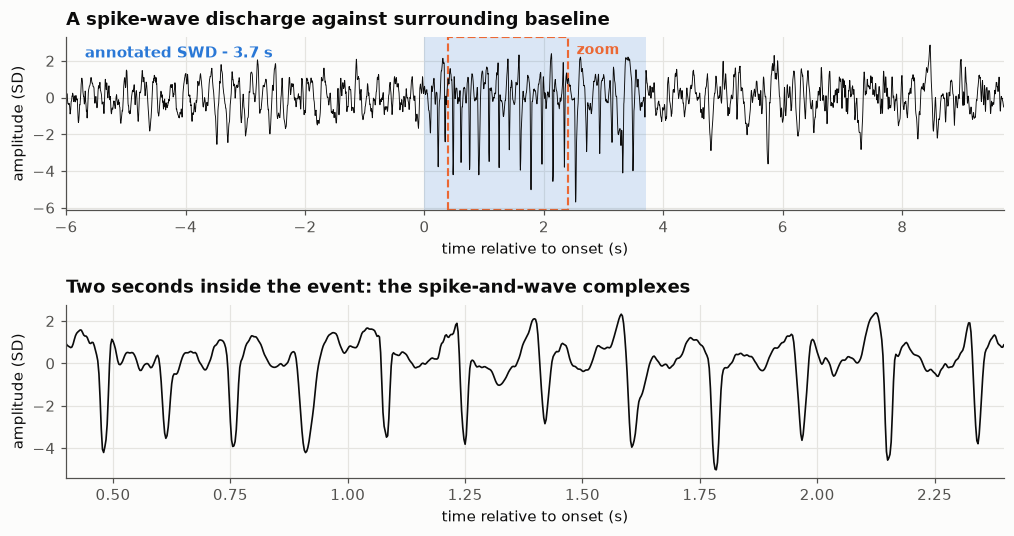

In [7]:
# An event of near-median duration, with context either side.
durations = ev[:, 1] - ev[:, 0]
pick = ev[np.argmin(np.abs(durations - np.median(durations)))]
pad = 6.0
lo, hi = int((pick[0] - pad) * fs), int((pick[1] + pad) * fs)
t = np.arange(lo, hi) / fs - pick[0]

# A 2 s excerpt from inside the event, where the complexes are legible.
zlo = int((pick[0] + 0.4) * fs)
zhi = zlo + int(2.0 * fs)
tz = np.arange(zlo, zhi) / fs - pick[0]

fig, axes = plt.subplots(2, 1, figsize=(11, 5.2),
                         gridspec_kw={"height_ratios": [1, 1], "hspace": 0.55})

axes[0].plot(t, x[lo:hi], color=INK, linewidth=0.6)
axes[0].axvspan(0, pick[1] - pick[0], color=SWD, alpha=0.16, linewidth=0)
axes[0].axvspan(tz[0], tz[-1], facecolor="none", edgecolor=BASE,
                linewidth=1.4, linestyle="--")
axes[0].text(0.02, 0.95, f"annotated SWD - {pick[1] - pick[0]:.1f} s",
             transform=axes[0].transAxes, color=SWD, fontweight="bold", va="top")
axes[0].text(tz[-1] + 0.15, axes[0].get_ylim()[1] * 0.72, "zoom",
             color=BASE, fontsize=9, fontweight="bold")
axes[0].set_xlabel("time relative to onset (s)")
axes[0].set_ylabel("amplitude (SD)")
axes[0].set_title("A spike-wave discharge against surrounding baseline",
                  loc="left", fontweight="bold", pad=8)
axes[0].set_xlim(t[0], t[-1])

axes[1].plot(tz, x[zlo:zhi], color=INK, linewidth=1.1)
axes[1].set_xlabel("time relative to onset (s)")
axes[1].set_ylabel("amplitude (SD)")
axes[1].set_title("Two seconds inside the event: the spike-and-wave complexes",
                  loc="left", fontweight="bold", pad=8)
axes[1].set_xlim(tz[0], tz[-1])
for spine in ("top", "right"):
    axes[1].spines[spine].set_visible(False)

plt.show()

The lower panel is the waveform the whole project turns on: a sharp negative **spike**
followed by a slower **wave**, repeating at roughly 6 Hz. Counting those repetitions gives
the fundamental; the sharpness of the spike is what deposits energy in the harmonics, and
it is the feature that ordinary theta rhythm does not have.

## 3. Event durations and gaps set the post-processing rules

The project specification assumes SWDs last "about a second or more". They do not:
the median is **5.6 seconds**. That single measurement changes the window length, the
minimum-duration rule, and the scoring tolerance.

In [8]:
dur = all_event_durations()
gap = all_event_gaps()

qs = np.percentile(dur, [1, 25, 50, 75, 99])
print(f"durations (n={len(dur)}): median {np.median(dur):.2f} s   "
      f"IQR {qs[1]:.2f}-{qs[3]:.2f} s   1st-99th {qs[0]:.2f}-{qs[4]:.2f} s   "
      f"max {dur.max():.1f} s")
print(f"gaps      (n={len(gap)}): median {np.median(gap):.1f} s   "
      f"min {gap.min():.3f} s")
print()
for t_ in (0.5, 1.0, 1.5):
    print(f"  true events shorter than {t_:.1f} s: {100 * (dur < t_).mean():.2f}%")
for t_ in (0.25, 0.5, 1.0, 2.0):
    print(f"  true gaps  shorter than {t_:.1f} s: {100 * (gap < t_).mean():.2f}%")

durations (n=24460): median 5.60 s   IQR 4.10-7.10 s   1st-99th 1.60-12.90 s   max 31.2 s
gaps      (n=24410): median 29.7 s   min 0.019 s

  true events shorter than 0.5 s: 0.00%
  true events shorter than 1.0 s: 0.02%
  true events shorter than 1.5 s: 0.58%
  true gaps  shorter than 0.2 s: 0.34%
  true gaps  shorter than 0.5 s: 0.86%
  true gaps  shorter than 1.0 s: 1.75%
  true gaps  shorter than 2.0 s: 4.05%


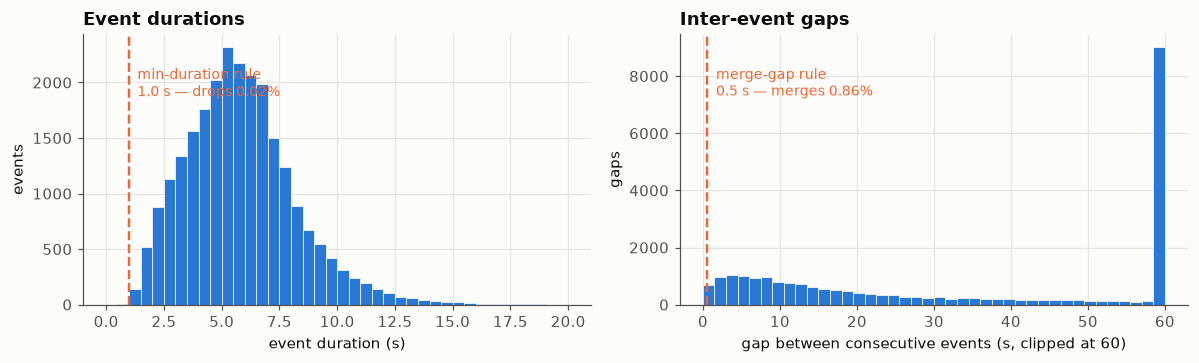

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))

axes[0].hist(dur, bins=np.arange(0, 20.25, 0.5), color=SWD, edgecolor=SURFACE, linewidth=0.5)
axes[0].axvline(config.MIN_DURATION_S, color=BASE, linestyle="--", linewidth=1.6)
axes[0].text(config.MIN_DURATION_S + 0.35, axes[0].get_ylim()[1] * 0.88,
             f"min-duration rule\n{config.MIN_DURATION_S:.1f} s — drops 0.02%",
             color=BASE, fontsize=9, va="top")
axes[0].set_xlabel("event duration (s)")
axes[0].set_ylabel("events")
axes[0].set_title("Event durations", loc="left", fontweight="bold")

axes[1].hist(np.clip(gap, 0, 60), bins=np.arange(0, 60.5, 1.5),
             color=SWD, edgecolor=SURFACE, linewidth=0.5)
axes[1].axvline(config.MERGE_GAP_S, color=BASE, linestyle="--", linewidth=1.6)
axes[1].text(config.MERGE_GAP_S + 1.2, axes[1].get_ylim()[1] * 0.88,
             f"merge-gap rule\n{config.MERGE_GAP_S:.1f} s — merges 0.86%",
             color=BASE, fontsize=9, va="top")
axes[1].set_xlabel("gap between consecutive events (s, clipped at 60)")
axes[1].set_ylabel("gaps")
axes[1].set_title("Inter-event gaps", loc="left", fontweight="bold")

plt.tight_layout()
plt.show()

Both post-processing rules are set from these distributions rather than convention:

- **Minimum duration 1.0 s** discards 0.02% of real events, and matches the floor the
  annotators evidently applied themselves.
- **Merge gap 0.5 s** wrongly fuses 0.86% of genuinely separate annotated pairs. Doubling
  it to 1.0 s would double that to 1.75%. Annotators *do* separate events across
  sub-second gaps — the smallest real gap is 19 milliseconds — so merging harder destroys
  real structure to fix model flicker.

## 4. The central problem: the SWD band is not exclusive to SWDs

This is the finding that shapes the entire feature design, and it needs care, because
the naive version of it is wrong.

Averaged over a whole 24-hour recording, the baseline spectrum peaks around **1.6 Hz** —
the slow activity of sleep dominates the average, and it looks nothing like an SWD. That
comparison is misleading, though: the classifier never sees a 24-hour average. It sees one
2-second window at a time.

Per window, the picture reverses.

In [10]:
from scipy import signal as sps

xs = frame(x, fs)
ys = frame_labels(y, fs)
f2, P = sps.welch(xs, fs, nperseg=512, axis=1)

in_band = (f2 >= 4) & (f2 <= 9)
total = (f2 >= 1) & (f2 <= 100)
rel_power = np.trapezoid(P[:, in_band], f2[in_band], axis=1) / np.trapezoid(
    P[:, total], f2[total], axis=1
)
dominant = f2[np.argmax(np.where(total, P, 0), axis=1)]

is_swd = ys > 0.8
is_base = ys == 0
theta_like = ((dominant >= 5) & (dominant <= 7))[is_base].mean()
overlap = (rel_power[is_base] > np.percentile(rel_power[is_swd], 5)).mean()

print(f"windows: {is_swd.sum()} SWD, {is_base.sum()} baseline")
print(f"baseline windows peaking at 5-7 Hz:                     {100 * theta_like:.1f}%")
print(f"baseline windows above the 5th-pct SWD 4-9 Hz power:    {100 * overlap:.1f}%")

windows: 2523 SWD, 156557 baseline
baseline windows peaking at 5-7 Hz:                     22.4%
baseline windows above the 5th-pct SWD 4-9 Hz power:    44.5%


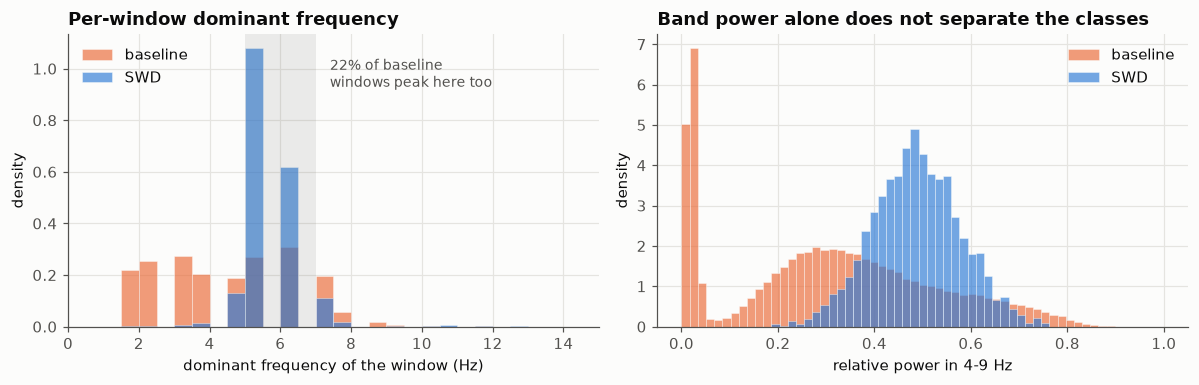

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

bins = np.arange(0, 20.5, 0.5)
for m, c, lab in ((is_base, BASE, "baseline"), (is_swd, SWD, "SWD")):
    axes[0].hist(dominant[m], bins=bins, density=True, color=c, alpha=0.65,
                 label=lab, edgecolor=SURFACE, linewidth=0.4)
axes[0].axvspan(5, 7, color=MUTED, alpha=0.10, linewidth=0)
axes[0].text(7.4, axes[0].get_ylim()[1] * 0.82,
             f"{100 * theta_like:.0f}% of baseline\nwindows peak here too",
             color=MUTED, fontsize=9)
axes[0].set_xlabel("dominant frequency of the window (Hz)")
axes[0].set_ylabel("density")
axes[0].set_title("Per-window dominant frequency", loc="left", fontweight="bold")
axes[0].set_xlim(0, 15)
axes[0].legend(frameon=False)

bins2 = np.linspace(0, 1, 60)
for m, c, lab in ((is_base, BASE, "baseline"), (is_swd, SWD, "SWD")):
    axes[1].hist(rel_power[m], bins=bins2, density=True, color=c, alpha=0.65,
                 label=lab, edgecolor=SURFACE, linewidth=0.4)
axes[1].set_xlabel("relative power in 4-9 Hz")
axes[1].set_ylabel("density")
axes[1].set_title("Band power alone does not separate the classes", loc="left",
                  fontweight="bold")
axes[1].legend(frameon=False)

plt.tight_layout()
plt.show()

Roughly **a quarter of all non-seizure windows have their spectral peak in 5–7 Hz** — the
same place the SWD fundamental sits. That is rodent theta rhythm, entirely normal activity
during exploration and REM sleep, and it occupies the band we would most naturally reach
for.

The right-hand panel is the consequence: the distributions of 4–9 Hz relative band power
overlap heavily. Measured across recordings, **47–75% of baseline windows exceed the
5th-percentile SWD window** on this feature. A detector built on band power at the
fundamental would be swamped by false positives.

This is the actual feature-engineering problem, and it is why the feature set cannot stop
at spectral power:

- **harmonics** — a spike-and-wave complex is not a sine wave, so it deposits energy at
  12, 18, 24 Hz; theta does not
- **morphology** — line length and amplitude capture the sharp spike that theta lacks
- **rhythmicity** — autocorrelation structure separates a regular spike train from an
  equally-powered but irregular oscillation

Note also that the SWD peak is stable at **5.5–5.9 Hz** across every recording checked,
while the baseline average peak varies with how much of the session was spent asleep. The
signal we are chasing is consistent; the background is not.

## 5. Burden is animal-specific and stable within animal

Seizure burden varies several-fold between mice, and is consistent across the five days
of each mouse. This matters twice over: it is what makes burden a meaningful scientific
readout, and it means an 8-fold leave-one-animal-out will have genuine variance between
folds. Reporting a single averaged score across folds would hide that.

In [12]:
train = table.filter(pl.col("split") == "train")
per_mouse = (
    train.group_by("mouse")
    .agg(
        pl.col("positive_pct").mean().alias("mean_pct"),
        pl.col("positive_pct").min().alias("min_pct"),
        pl.col("positive_pct").max().alias("max_pct"),
        pl.col("events_per_hour").mean().alias("events_per_hour"),
    )
    .sort("mean_pct", descending=True)
)
print(per_mouse)

shape: (8, 5)
┌──────────┬──────────┬──────────┬──────────┬─────────────────┐
│ mouse    ┆ mean_pct ┆ min_pct  ┆ max_pct  ┆ events_per_hour │
│ ---      ┆ ---      ┆ ---      ┆ ---      ┆ ---             │
│ str      ┆ f64      ┆ f64      ┆ f64      ┆ f64             │
╞══════════╪══════════╪══════════╪══════════╪═════════════════╡
│ train_M3 ┆ 6.358033 ┆ 5.284878 ┆ 7.33118  ┆ 27.863241       │
│ train_M1 ┆ 5.205602 ┆ 3.820184 ┆ 6.501238 ┆ 38.128445       │
│ train_M4 ┆ 4.049718 ┆ 1.343929 ┆ 9.076331 ┆ 21.582266       │
│ train_M6 ┆ 3.803209 ┆ 3.126172 ┆ 4.415025 ┆ 19.216147       │
│ train_M8 ┆ 3.759294 ┆ 2.310662 ┆ 4.388632 ┆ 33.754072       │
│ train_M5 ┆ 3.240327 ┆ 2.160047 ┆ 4.440582 ┆ 18.90849        │
│ train_M9 ┆ 2.890891 ┆ 2.480986 ┆ 3.261056 ┆ 19.578624       │
│ train_M2 ┆ 1.320821 ┆ 1.100419 ┆ 1.555775 ┆ 9.223029        │
└──────────┴──────────┴──────────┴──────────┴─────────────────┘


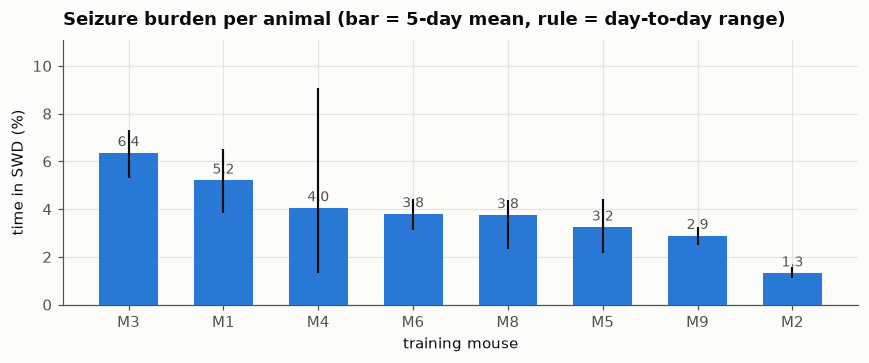

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.4))
labels = [m.replace("train_", "") for m in per_mouse["mouse"]]
xs = np.arange(len(labels))

# Magnitude, not identity: one hue, with the observed across-day range as a rule.
ax.bar(xs, per_mouse["mean_pct"], color=SWD, width=0.62, zorder=3)
ax.vlines(xs, per_mouse["min_pct"], per_mouse["max_pct"], color=INK, linewidth=1.4, zorder=4)
for xi, v in zip(xs, per_mouse["mean_pct"]):
    ax.text(xi, v + 0.28, f"{v:.1f}", ha="center", color=MUTED, fontsize=9)

ax.set_xticks(xs, labels)
ax.set_xlabel("training mouse")
ax.set_ylabel("time in SWD (%)")
ax.set_title("Seizure burden per animal (bar = 5-day mean, rule = day-to-day range)",
             loc="left", fontweight="bold", pad=10)
ax.set_ylim(0, per_mouse["max_pct"].max() * 1.22)
plt.tight_layout()
plt.show()

## What this means for the pipeline

| finding | consequence |
|---|---|
| 1000 Hz train vs 400 Hz test | resample everything to 400 Hz; the split confounds animal, session **and** acquisition hardware |
| `mID` unreliable, numbers collide across splits | group by filename, namespaced per split |
| test set cropped at 100 seizures | burden statistics from the training split only |
| recordings start/end mid-event | zero-pad before run-length event extraction |
| median event 5.6 s, not ~1 s | 2 s windows; minimum duration 1.0 s |
| 0.86% of gaps below 0.5 s | merge gap 0.5 s, no wider |
| theta shares the SWD fundamental | features must use harmonics, amplitude and rhythmicity — not peak frequency |
| burden varies 4× across animals | leave-one-animal-out, reported per animal with spread |

Next: the Phase 1 skeleton — a deliberately minimal model carried through the complete
chain to event-level metrics, producing an honest baseline that every later change is
measured against.